# SofaScore-derived Kickbase metric consistency

Which point contributions repeat across each team's **last five matches across
competitions**, and which should inform a next-match prediction?

**1 — Generally consistent**; **2 — Consistent for in-form players**;
**3 — Volatile: exclude from this prediction approach**.
Grey cells mean **unclassified**, not proven volatility. These are exploratory
classifications within a short window, conditional on players already included
by the source export's eligibility rules. They do not change any prediction model.

Form uses the existing minute-group Kickbase percentile ratings, goalkeeper
calibration where available, and recency weights **28/24/20/16/12**. Top 20% is
selected **within each position**, including cutoff ties. Current form tables are
descriptive. Predictive classifications use form recomputed **strictly before
each target kickoff**, including the percentile comparison population.

In [1]:
import sys
import json
from pathlib import Path
from dataclasses import asdict
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio
from plotly.subplots import make_subplots
from IPython.display import display, HTML, Markdown

PROJECT_ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
                     if (p / 'project_paths.py').is_file()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Run this notebook from within the project directory.')
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from sofascore_metric_consistency import Settings, LABELS, load_inputs, analyze

pio.templates.default = 'plotly_white'
_plotly_loaded = False
def show_figure(fig):
    # Save both native Plotly MIME and HTML with the JS library embedded once.
    # All plots and dropdowns work without a CDN or widget kernel connection.
    global _plotly_loaded
    html = pio.to_html(fig, include_plotlyjs=not _plotly_loaded,
                       full_html=False, config={'displaylogo': False, 'responsive': True})
    _plotly_loaded = True
    display({'text/html': html, 'application/vnd.plotly.v1+json': json.loads(fig.to_json())}, raw=True)

pd.set_option('display.max_colwidth', None)
pd.set_option('display.max_rows', None)

## Editable configuration

Leave `SOURCE_FILE` as `None` to use the latest points export. An explicit path
pins a run. Adjust thresholds and rerun all cells. `MANUAL_OVERRIDES` maps
`(metric_id, position)` to category `1`, `2` or `3`; automatic decisions and
evidence status stay visible. Overrides express judgement, not additional evidence.

In [2]:
SOURCE_FILE = None
BUNDESLIGA_MATCHDAY = None  # None: use the source export's matchday; override with 1–34.
FORM_TOP_PERCENT = 20
MINIMUM_MINUTES = 45
MINIMUM_HISTORY = 2
MINIMUM_PLAYERS = 20
MINIMUM_EVALUATIONS = 30
MINIMUM_NONZERO = 0.20
MINIMUM_RECURRENCE = 0.60
MAXIMUM_WAPE = 0.75
MANUAL_OVERRIDES = {}  # Example: {('goal', 'FWD'): 3}
DETAIL_PLAYERS = 8

settings = Settings(bundesliga_matchday=BUNDESLIGA_MATCHDAY,
    form_top_percent=FORM_TOP_PERCENT, minimum_minutes=MINIMUM_MINUTES,
    minimum_history=MINIMUM_HISTORY, minimum_players=MINIMUM_PLAYERS,
    minimum_evaluations=MINIMUM_EVALUATIONS, minimum_nonzero=MINIMUM_NONZERO,
    minimum_recurrence=MINIMUM_RECURRENCE, maximum_wape=MAXIMUM_WAPE)
payload, snapshot, catalog, provenance = load_inputs(SOURCE_FILE)
result = analyze(payload, snapshot, catalog, settings, MANUAL_OVERRIDES)
appearances = result['appearances']
metrics = result['metrics']
evaluations = result['evaluations']
positions = result['by_position']
overall = result['overall']
current_form = result['current_form']
metadata = result['metadata']
display(pd.Series({k: v for k, v in provenance.items()
                   if k not in ('scoring_policy', 'failed_matches', 'eligibility')}, name='Source'))
display(pd.Series(asdict(settings), name='Applied configuration'))
display(pd.Series(result['coverage'], name='Coverage'))
display(Markdown('**Source eligibility:** `' + json.dumps(provenance['eligibility']) + '`'))
if provenance['failed_matches']:
    display(Markdown('**Failed source entries — excluded, never filled with zeros:**'))
    display(pd.DataFrame(provenance['failed_matches']))

points_file       C:\kickbase project\outputs\sofascore\player_kickbase_point_averages\overall_player_kickbase_point_averages_2026-10-08_15-15-35_109329+0200.json
team_form_file                                                      C:\kickbase project\outputs\sofascore\team_form\team_form_2026-10-08_15-14-18_764489+0200.json
generated_at                                                                                                                             2026-10-08T15:15:35+02:00
Name: Source, dtype: str

bundesliga_matchday      NaN
form_top_percent       20.00
minimum_minutes        45.00
minimum_history         2.00
minimum_players        20.00
minimum_evaluations    30.00
minimum_nonzero         0.20
minimum_recurrence      0.60
maximum_wape            0.75
Name: Applied configuration, dtype: float64

source                                            1042
invalid_points_or_minutes                            0
below_10_minutes                                    44
valid_appearances                                 1042
analysis_appearances                               804
qualification_matchday                               5
minimum_matchday_appearances                         3
players_excluded_by_matchday_qualification           0
appearances_excluded_by_matchday_qualification       0
failed_matches                                      15
teams                                               18
players                                            273
below_analysis_minutes                             238
Name: Coverage, dtype: int64

**Source eligibility:** `{"bundesliga_matchday": 5, "appearance_definition": "starter or player recorded as substituted on", "minimum_appearances": 3, "latest_match_exception": false, "latest_two_matches_exception": true, "latest_match_minutes_exception": {"enabled": true, "minimum_minutes": 45}, "goalkeeper_appearance_exception": "One appearance in the sampled last five matches."}`

**Failed source entries — excluded, never filled with zeros:**

,match_id,team_id,team,category,error
0,17157914,2677,VfB Stuttgart,overall,KickbaseApproximationError: Shot-map response has no shotmap list.
1,17212342,2677,VfB Stuttgart,overall,KickbaseApproximationError: Shot-map response has no shotmap list.
2,17213101,2671,1. FC Köln,overall,KickbaseApproximationError: Shot-map response has no shotmap list.
3,17184536,2547,1. FC Union Berlin,overall,KickbaseApproximationError: Shot-map response has no shotmap list.
4,17212996,2674,Eintracht Frankfurt,overall,KickbaseApproximationError: Shot-map response has no shotmap list.
5,17213068,2556,1. FSV Mainz 05,overall,KickbaseApproximationError: Shot-map response has no shotmap list.
6,17059733,2561,SC Paderborn 07,overall,KickbaseApproximationError: Shot-map response has no shotmap list.
7,17156906,2527,Borussia M'gladbach,overall,KickbaseApproximationError: Shot-map response has no shotmap list.
8,17226830,2527,Borussia M'gladbach,overall,KickbaseApproximationError: Shot-map response has no shotmap list.
9,17213134,2676,Hamburger SV,overall,KickbaseApproximationError: Shot-map response has no shotmap list.


## Minimum matchday qualification

This notebook also applies the shared player qualification rules used by the
derived Kickbase export:

| Bundesliga matchday | Minimum appearances | Alternative qualification |
|---|---:|---|
| 1 | 1 | — |
| 2–3 | 2 | An appearance in the latest available team match |
| 4–34 | 3 | Appearances in both latest available team matches, or 45+ minutes in the latest one |
| Goalkeepers, any matchday | 1 | One recorded appearance in the sampled history |

Qualification counts recorded appearances **before** applying the separate
10-minute rating or configurable consistency-minute filters. A player meeting
an exception can qualify with fewer than the standard minimum appearances.

`BUNDESLIGA_MATCHDAY = None` reads the source export's matchday. The selected
matchday regime is applied at each pre-match cutoff using **only earlier matches**;
mixed-competition team slots do not reveal historical Bundesliga round numbers.
This is a consistent qualification policy, not a reconstruction of past rounds.
Minimum forecast history remains an additional requirement. The source has already
removed some players, so lowering qualification here cannot recover those players.

In [3]:
qualification = result['qualification']
display(pd.Series(result['qualification_policy'], name='Applied matchday qualification'))
display(qualification.groupby(['position', 'qualified', 'qualification_route']).size()
    .rename('Players').to_frame())
display(qualification[['player_name', 'team', 'position', 'recorded_appearances',
    'minimum_appearances', 'latest_match_minutes', 'qualified', 'qualification_route']])
if not evaluations.empty:
    assert evaluations.matchday_qualified.all()
    display(evaluations[['team_id', 'player_id', 'match_id', 'kickoff', 'position',
        'history_count', 'matchday_qualified']].drop_duplicates()
        .groupby('position').size().rename('Qualified pre-match checks').to_frame())

bundesliga_matchday                                                               5
appearance_definition                  starter or player recorded as substituted on
minimum_appearances                                                               3
latest_match_exception                                                        False
latest_two_matches_exception                                                   True
latest_match_minutes_exception             {'enabled': True, 'minimum_minutes': 45}
goalkeeper_appearance_exception    One appearance in the sampled last five matches.
Name: Applied matchday qualification, dtype: object

Players
position qualified qualification_route                               
DEF      True      Both latest team matches (MD4+ exception)        2
                   Minimum 3 recorded appearances                  79
FWD      True      Both latest team matches (MD4+ exception)        1
                   Minimum 3 recorded appearances                  59
GK       True      Goalkeeper: one recorded appearance             22
MID      True      Minimum 3 recorded appearances                 110

,player_name,team,position,recorded_appearances,minimum_appearances,latest_match_minutes,qualified,qualification_route
0,Michael Olise,FC Bayern München,MID,5,3,90.0,True,Minimum 3 recorded appearances
1,Harry Kane,FC Bayern München,FWD,5,3,77.0,True,Minimum 3 recorded appearances
2,Joshua Kimmich,FC Bayern München,MID,5,3,90.0,True,Minimum 3 recorded appearances
3,Jonathan Tah,FC Bayern München,DEF,4,3,90.0,True,Minimum 3 recorded appearances
4,Alphonso Davies,FC Bayern München,DEF,5,3,83.0,True,Minimum 3 recorded appearances
5,Aleksandar Pavlović,FC Bayern München,MID,5,3,63.0,True,Minimum 3 recorded appearances
6,Dayot Upamecano,FC Bayern München,DEF,4,3,45.0,True,Minimum 3 recorded appearances
7,Jamal Musiala,FC Bayern München,MID,4,3,90.0,True,Minimum 3 recorded appearances
8,Josip Stanišić,FC Bayern München,DEF,4,3,90.0,True,Minimum 3 recorded appearances
9,Tom Bischof,FC Bayern München,MID,5,3,27.0,True,Minimum 3 recorded appearances


,Qualified pre-match checks
position,
DEF,67
FWD,30
GK,19
MID,82


## Match window and reconciliation

Slots 1–5 mean oldest to newest in **each team's own history**, not shared league
rounds. The forecast checks use slots 4 and 5; a team with fewer than four slots
has no target check. A missing appearance stays missing. A missing metric award
becomes zero only within a valid, recorded appearance for an applicable position.

Metric awards must sum to raw event-derived match points. Goalkeeper calibration
changes form-rating totals, but its adjustment is kept separate from metric awards.

In [4]:
window = metadata.copy()
window['date_Berlin'] = window.kickoff.dt.tz_convert('Europe/Berlin').dt.strftime('%Y-%m-%d %H:%M')
display(window[['team', 'slot', 'date_Berlin', 'opponent', 'competition', 'match_id']])
assert np.allclose(appearances.award_total, appearances.raw_points)
display(appearances.groupby('position').agg(appearances=('match_id', 'size'),
    raw_points=('raw_points', 'sum'), award_points=('award_total', 'sum'),
    calibration_adjustment=('calibration_adjustment', 'sum')))
gk_adjustments = appearances.loc[appearances.position == 'GK',
    ['player_name', 'kickoff', 'opponent', 'raw_points', 'rating_points', 'calibration_adjustment']]
display(gk_adjustments)

,team,slot,date_Berlin,opponent,competition,match_id
0,FC Bayern München,1,2026-09-02 20:45,VfL Osnabrück,DFB Pokal,16287047
1,FC Bayern München,2,2026-09-05 18:30,FC Schalke 04,Bundesliga,16434032
2,FC Bayern München,3,2026-09-10 21:00,Bodø/Glimt,UEFA Champions League,16938858
3,FC Bayern München,4,2026-09-13 17:30,SV 07 Elversberg,Bundesliga,16434041
4,FC Bayern München,5,2026-09-18 20:30,1. FC Union Berlin,Bundesliga,16434038
5,VfB Stuttgart,1,2026-09-09 18:45,Viking FK,UEFA Champions League,16939028
6,VfB Stuttgart,2,2026-09-12 15:30,TSG Hoffenheim,Bundesliga,16434035
7,VfB Stuttgart,3,2026-09-19 18:30,Borussia Dortmund,Bundesliga,16434034
8,VfB Stuttgart,4,2026-09-25 16:30,1. FC Heidenheim,Club Friendly Games,17157914
9,VfB Stuttgart,5,2026-10-01 17:30,SpVgg Greuther Fürth,Club Friendly Games,17212342


,appearances,raw_points,award_points,calibration_adjustment
position,,,,
DEF,311,27814,27814,0
FWD,225,14789,14789,0
GK,75,5733,5733,1208
MID,431,36486,36486,0


,player_name,kickoff,opponent,raw_points,rating_points,calibration_adjustment
46,Manuel Neuer,2026-09-05 16:30:00+00:00,FC Schalke 04,84,84,0
47,Manuel Neuer,2026-09-18 18:30:00+00:00,1. FC Union Berlin,166,171,5
48,Manuel Neuer,2026-09-10 19:00:00+00:00,Bodø/Glimt,127,127,0
69,Jonas Urbig,2026-09-02 18:45:00+00:00,VfL Osnabrück,49,49,0
70,Jonas Urbig,2026-09-13 15:30:00+00:00,SV 07 Elversberg,79,79,0
87,Fabian Bredlow,2026-09-19 16:30:00+00:00,Borussia Dortmund,5,21,16
88,Fabian Bredlow,2026-09-12 13:30:00+00:00,TSG Hoffenheim,78,122,44
89,Fabian Bredlow,2026-09-09 16:45:00+00:00,Viking FK,86,86,0
117,Marvin Schwäbe,2026-08-29 13:30:00+00:00,TSG Hoffenheim,172,172,0
118,Marvin Schwäbe,2026-09-12 16:30:00+00:00,SV Werder Bremen,71,116,45


## Current in-form players

The full-window, recency-weighted percentile rating is ranked within position
after the minimum matchday qualification rules above.
`ceil(position population × FORM_TOP_PERCENT / 100)` determines the cutoff;
ties can increase the selected proportion. Players need at least one valid
appearance of 10+ minutes for this descriptive table; pre-match form checks
require both pre-match matchday qualification and at least `MINIMUM_HISTORY`
earlier appearances of 10+ minutes.

In [5]:
form_sizes = current_form.groupby('position').agg(eligible_players=('player_id', 'size'),
    selected=('in_form', 'sum'), rating_cutoff=('form_cutoff', 'first'))
form_sizes['selected_percent'] = 100 * form_sizes.selected / form_sizes.eligible_players
display(form_sizes)
for position in ['GK', 'DEF', 'MID', 'FWD']:
    display(Markdown(f'### {position}'))
    display(current_form.loc[(current_form.position == position) & current_form.in_form,
        ['player_name', 'team', 'rating_count', 'average_rating']]
        .sort_values('average_rating', ascending=False).reset_index(drop=True))

,eligible_players,selected,rating_cutoff,selected_percent
position,,,,
DEF,81,20,7.9,24.691358
FWD,60,12,7.7,20.000000
GK,22,5,7.6,22.727273
MID,110,22,7.8,20.000000


### GK

,player_name,team,rating_count,average_rating
0,Manuel Neuer,FC Bayern München,3,8.0
1,Alexander Meyer,Borussia Dortmund,1,7.9
2,Alexander Schwolow,1. FSV Mainz 05,2,7.8
3,Loris Karius,FC Schalke 04,3,7.7
4,Finn Dahmen,FC Augsburg,4,7.6


### DEF

,player_name,team,rating_count,average_rating
0,Alphonso Davies,FC Bayern München,5,9.1
1,Jonathan Tah,FC Bayern München,4,9.0
2,Ramy Bensebaini,Borussia Dortmund,1,8.9
3,Dayot Upamecano,FC Bayern München,4,8.6
4,Miguel Gutiérrez,Bayer 04 Leverkusen,4,8.6
5,Kim Min-jae,FC Bayern München,3,8.5
6,Konrad Laimer,FC Bayern München,2,8.5
7,Jonah Sticker,SC Paderborn 07,2,8.4
8,Robin Koch,Eintracht Frankfurt,4,8.4
9,Maximilian Mittelstädt,VfB Stuttgart,3,8.4


### MID

,player_name,team,rating_count,average_rating
0,Michael Olise,FC Bayern München,5,9.6
1,Aleksandar Pavlović,FC Bayern München,5,9.4
2,Joshua Kimmich,FC Bayern München,5,9.2
3,Tom Bischof,FC Bayern München,5,9.1
4,Vincenzo Grifo,SC Freiburg,3,8.7
5,Lennart Karl,FC Bayern München,4,8.7
6,Aleix García,Bayer 04 Leverkusen,5,8.7
7,Jamal Musiala,FC Bayern München,4,8.6
8,Felix Nmecha,Borussia Dortmund,5,8.5
9,Joey Veerman,Borussia Dortmund,5,8.4


### FWD

,player_name,team,rating_count,average_rating
0,Harry Kane,FC Bayern München,5,9.5
1,Patrik Schick,Bayer 04 Leverkusen,5,8.8
2,Fábio Silva,Borussia Dortmund,5,8.7
3,Serhou Guirassy,Borussia Dortmund,4,8.5
4,Jonathan Burkardt,Eintracht Frankfurt,4,8.1
5,Sheraldo Becker,1. FSV Mainz 05,4,8.1
6,Niclas Füllkrug,SV Werder Bremen,4,8.1
7,Christian Kofane,Bayer 04 Leverkusen,5,8.0
8,Adil Aouchiche,FC Schalke 04,3,7.9
9,Igor Matanović,SC Freiburg,4,7.9


## Metric-by-metric examination

Each check forecasts **points per 90** from the same player's earlier qualifying
appearances, weighted by team match slots. Weights are renormalised over available
appearances without moving absent slots. Form ranking excludes all matches at or
after the target kickoff, including other teams' matches.

**WAPE** = sum of absolute forecast errors / sum of absolute observed points.
A zero denominator gives no evidence of consistency. **Recurrence** is the share
of nonzero target contributions among checks where the player had any earlier
nonzero contribution. Negative points retain their sign in forecasts.

A cohort passes only if it meets **all** configured sample, nonzero-frequency,
recurrence and WAPE thresholds. Category 1 takes precedence over category 2.
Category 3 requires adequate evidence in both cohorts and neither passing.
Small cohorts stay unclassified; the default 20-player/30-check rule can make
position-specific form cohorts too small in a five-match window.

Overall category 1 requires every applicable position to pass for all players;
overall category 2 requires every applicable position's form cohort to pass.
Applicability follows catalog rules and the scorer's implementation. Catalog-only
metrics remain unsupported. Spatial alternatives are reported through their emitted
proxy family, avoiding double counting. Statistical stability of a proxy does not
establish its accuracy against official Kickbase points.

In [6]:
display(Markdown('### Overall classification'))
display(overall[['metric_id', 'classification', 'evidence_status', 'position_details', 'confidence']])
display(Markdown('### Position-specific decisions and evidence'))
decision_columns = ['metric_id', 'position', 'automatic_category', 'category', 'overridden',
    'classification', 'evidence_status', 'all_players', 'all_evaluations',
    'all_nonzero_frequency', 'all_recurrence', 'all_wape', 'form_players',
    'form_evaluations', 'form_nonzero_frequency', 'form_recurrence', 'form_wape', 'reason']
display(positions.loc[positions.supported, decision_columns].round(3))
display(Markdown('### Descriptive contribution and within-player variation'))
descriptive_columns = ['metric_id', 'position', 'appearances', 'players', 'nonzero_frequency',
    'mean_points', 'median_points', 'std_points', 'mean_per_90', 'median_per_90',
    'iqr_per_90', 'median_within_player_cv', 'within_player_samples', 'confidence']
display(positions.loc[positions.supported, descriptive_columns].round(3))
display(Markdown('Within-player CV = population standard deviation / mean absolute points per 90; '
    'only players with 3+ appearances and 2+ nonzero contributions contribute. Zero-only players '
    'cannot make this diagnostic look stable. It is descriptive, not an extra classification threshold.'))
display(Markdown('### Catalog metrics not independently emitted'))
display(positions.loc[~positions.supported, ['metric_id', 'implementation']].drop_duplicates())

### Overall classification

,metric_id,classification,evidence_status,position_details,confidence
0,goal,Unclassified,insufficient evidence,GK: Unclassified (insufficient evidence); DEF: Unclassified (insufficient evidence); MID: Unclassified (insufficient evidence); FWD: Unclassified (insufficient evidence),direct
1,penalty_saved,Unclassified,insufficient evidence,GK: Unclassified (insufficient evidence),derived
2,penalty_scored,Unclassified,insufficient evidence,GK: Unclassified (insufficient evidence); DEF: Unclassified (insufficient evidence); MID: Unclassified (insufficient evidence); FWD: Unclassified (insufficient evidence),direct
3,assist,Unclassified,insufficient evidence,GK: Unclassified (insufficient evidence); DEF: Unclassified (insufficient evidence); MID: Unclassified (insufficient evidence); FWD: Unclassified (insufficient evidence),direct
4,shootout_penalty_saved,Unclassified,insufficient evidence,GK: Unclassified (insufficient evidence),No observed awards
5,secondary_assist,Unclassified,unsupported,GK: Unclassified (unsupported); DEF: Unclassified (unsupported); MID: Unclassified (unsupported); FWD: Unclassified (unsupported),No observed awards
6,shootout_penalty_scored,Unclassified,insufficient evidence,GK: Unclassified (insufficient evidence); DEF: Unclassified (insufficient evidence); MID: Unclassified (insufficient evidence); FWD: Unclassified (insufficient evidence),No observed awards
7,penalty_won,Unclassified,insufficient evidence,GK: Unclassified (insufficient evidence); DEF: Unclassified (insufficient evidence); MID: Unclassified (insufficient evidence); FWD: Unclassified (insufficient evidence),direct
8,own_goal_forced,Unclassified,unsupported,GK: Unclassified (unsupported); DEF: Unclassified (unsupported); MID: Unclassified (unsupported); FWD: Unclassified (unsupported),No observed awards
9,deflected_assist,Unclassified,unsupported,GK: Unclassified (unsupported); DEF: Unclassified (unsupported); MID: Unclassified (unsupported); FWD: Unclassified (unsupported),No observed awards


### Position-specific decisions and evidence

,metric_id,position,automatic_category,category,overridden,classification,evidence_status,all_players,all_evaluations,all_nonzero_frequency,all_recurrence,all_wape,form_players,form_evaluations,form_nonzero_frequency,form_recurrence,form_wape,reason
0,goal,GK,NaN,NaN,False,Unclassified,insufficient evidence,14,19,0.000,NaN,NaN,3,3,0.000,NaN,NaN,Insufficient evidence: 14 players / 19 evaluations; in form: Insufficient evidence: 3 players / 3 evaluations
1,goal,DEF,NaN,NaN,False,Unclassified,insufficient evidence,52,67,0.075,0.125,1.517,15,17,0.059,0.000,3.017,Nonzero frequency below threshold; Recurrence below threshold; Prediction error above threshold; in form: Insufficient evidence: 15 players / 17 evaluations
2,goal,MID,NaN,NaN,False,Unclassified,insufficient evidence,66,82,0.098,0.192,1.698,12,16,0.125,0.250,1.399,Nonzero frequency below threshold; Recurrence below threshold; Prediction error above threshold; in form: Insufficient evidence: 12 players / 16 evaluations
3,goal,FWD,NaN,NaN,False,Unclassified,insufficient evidence,24,30,0.367,0.409,1.392,9,12,0.417,0.455,1.432,Recurrence below threshold; Prediction error above threshold; in form: Insufficient evidence: 9 players / 12 evaluations
4,penalty_saved,GK,NaN,NaN,False,Unclassified,insufficient evidence,14,19,0.000,0.000,NaN,3,3,0.000,NaN,NaN,Insufficient evidence: 14 players / 19 evaluations; in form: Insufficient evidence: 3 players / 3 evaluations
5,penalty_scored,GK,NaN,NaN,False,Unclassified,insufficient evidence,14,19,0.000,NaN,NaN,3,3,0.000,NaN,NaN,Insufficient evidence: 14 players / 19 evaluations; in form: Insufficient evidence: 3 players / 3 evaluations
6,penalty_scored,DEF,NaN,NaN,False,Unclassified,insufficient evidence,52,67,0.000,NaN,NaN,15,17,0.000,NaN,NaN,No observed nonzero target contribution; Nonzero frequency below threshold; No previously active cases to measure recurrence; in form: Insufficient evidence: 15 players / 17 evaluations
7,penalty_scored,MID,NaN,NaN,False,Unclassified,insufficient evidence,66,82,0.000,NaN,NaN,12,16,0.000,NaN,NaN,No observed nonzero target contribution; Nonzero frequency below threshold; No previously active cases to measure recurrence; in form: Insufficient evidence: 12 players / 16 evaluations
8,penalty_scored,FWD,NaN,NaN,False,Unclassified,insufficient evidence,24,30,0.033,0.250,1.831,9,12,0.083,0.250,1.831,Nonzero frequency below threshold; Recurrence below threshold; Prediction error above threshold; in form: Insufficient evidence: 9 players / 12 evaluations
9,assist,GK,NaN,NaN,False,Unclassified,insufficient evidence,14,19,0.000,NaN,NaN,3,3,0.000,NaN,NaN,Insufficient evidence: 14 players / 19 evaluations; in form: Insufficient evidence: 3 players / 3 evaluations


### Descriptive contribution and within-player variation

,metric_id,position,appearances,players,nonzero_frequency,mean_points,median_points,std_points,mean_per_90,median_per_90,iqr_per_90,median_within_player_cv,within_player_samples,confidence
0,goal,GK,75,22,0.000,0.000,0.0,0.000,0.000,0.000,0.000,NaN,0,No observed awards
1,goal,DEF,256,74,0.047,4.648,0.0,20.970,4.926,0.000,0.000,1.012,2,direct
2,goal,MID,335,105,0.119,12.746,0.0,38.044,14.745,0.000,0.000,1.001,6,direct
3,goal,FWD,138,50,0.326,32.754,0.0,52.953,38.302,0.000,80.000,0.978,12,direct
4,penalty_saved,GK,75,22,0.040,4.000,0.0,19.596,4.000,0.000,0.000,NaN,0,derived
5,penalty_scored,GK,75,22,0.000,0.000,0.0,0.000,0.000,0.000,0.000,NaN,0,No observed awards
6,penalty_scored,DEF,256,74,0.000,0.000,0.0,0.000,0.000,0.000,0.000,NaN,0,No observed awards
7,penalty_scored,MID,335,105,0.000,0.000,0.0,0.000,0.000,0.000,0.000,NaN,0,No observed awards
8,penalty_scored,FWD,138,50,0.022,1.739,0.0,11.666,1.857,0.000,0.000,1.229,1,direct
9,assist,GK,75,22,0.000,0.000,0.0,0.000,0.000,0.000,0.000,NaN,0,No observed awards


Within-player CV = population standard deviation / mean absolute points per 90; only players with 3+ appearances and 2+ nonzero contributions contribute. Zero-only players cannot make this diagnostic look stable. It is descriptive, not an extra classification threshold.

### Catalog metrics not independently emitted

,metric_id,implementation
14,secondary_assist,Not independently emitted by the scorer
26,own_goal_forced,Not independently emitted by the scorer
30,deflected_assist,Not independently emitted by the scorer
34,deadly_pass,Not independently emitted by the scorer
38,rebound_assist,Not independently emitted by the scorer
42,woodwork_assist,Not independently emitted by the scorer
54,dive_save,Not independently emitted by the scorer
55,last_man_tackle,Not independently emitted by the scorer
64,challenged_collection,Not independently emitted by the scorer
82,left_post,Not independently emitted by the scorer


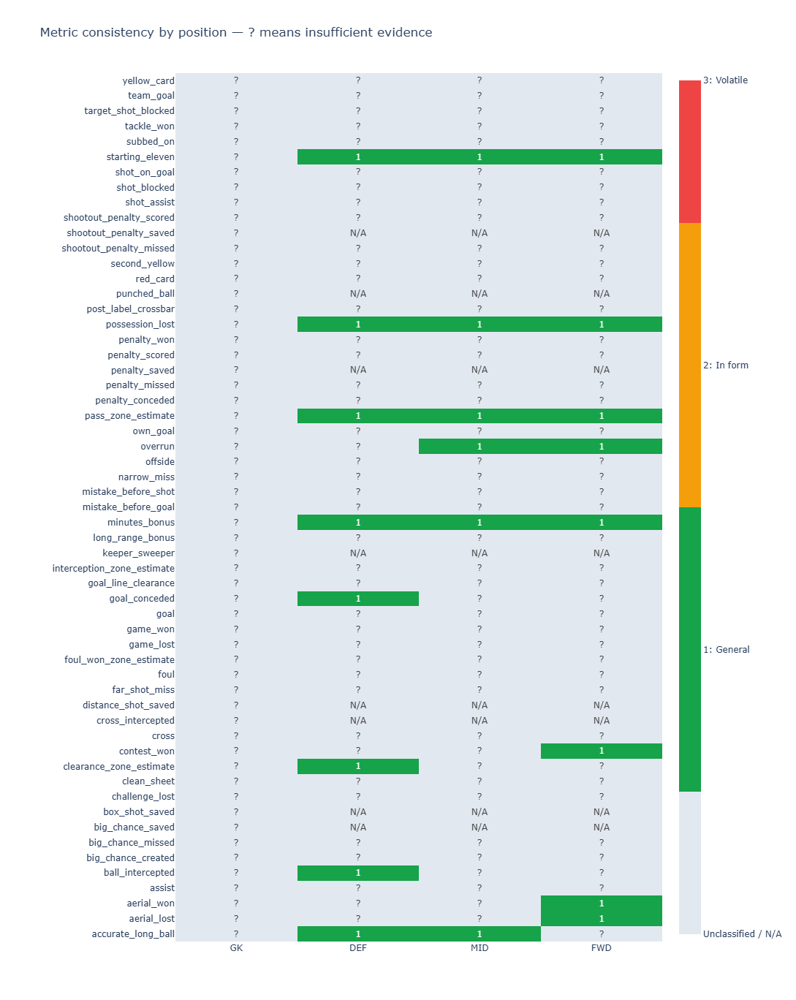

In [7]:
heat = positions.loc[positions.supported].copy()
metric_order = sorted(heat.metric_id.unique())
order = ['GK', 'DEF', 'MID', 'FWD']
values = heat.pivot(index='metric_id', columns='position', values='category').reindex(index=metric_order, columns=order)
reasons = heat.pivot(index='metric_id', columns='position', values='reason').reindex(index=metric_order, columns=order)
statuses = heat.pivot(index='metric_id', columns='position', values='evidence_status').reindex(index=metric_order, columns=order)
text = values.copy().astype(object)
for metric in metric_order:
    for position in order:
        value = values.loc[metric, position]
        text.loc[metric, position] = 'N/A' if pd.isna(statuses.loc[metric, position]) else ('?' if pd.isna(value) else str(int(value)))
fig = go.Figure(go.Heatmap(x=order, y=metric_order, z=values.fillna(0).values,
    text=text.values, texttemplate='%{text}', customdata=reasons.fillna('Not applicable').values,
    hovertemplate='%{y} / %{x}<br>%{customdata}<extra></extra>', zmin=0, zmax=3,
    colorscale=[[0, '#e2e8f0'], [.1666, '#e2e8f0'], [.1667, '#16a34a'], [.4999, '#16a34a'],
                [.5, '#f59e0b'], [.8332, '#f59e0b'], [.8333, '#ef4444'], [1, '#ef4444']],
    colorbar=dict(tickvals=[0, 1, 2, 3], ticktext=['Unclassified / N/A', '1: General', '2: In form', '3: Volatile'])))
fig.update_layout(title='Metric consistency by position — ? means insufficient evidence',
    height=max(900, len(metric_order)*24), margin=dict(l=240))
show_figure(fig)

## Contributions, distributions and match-slot trends

These charts compare the **current** full-window form cohort with all available
players. They describe the window; the classification above uses separate pre-match
form cohorts. Hover to see metric, position and contribution details.

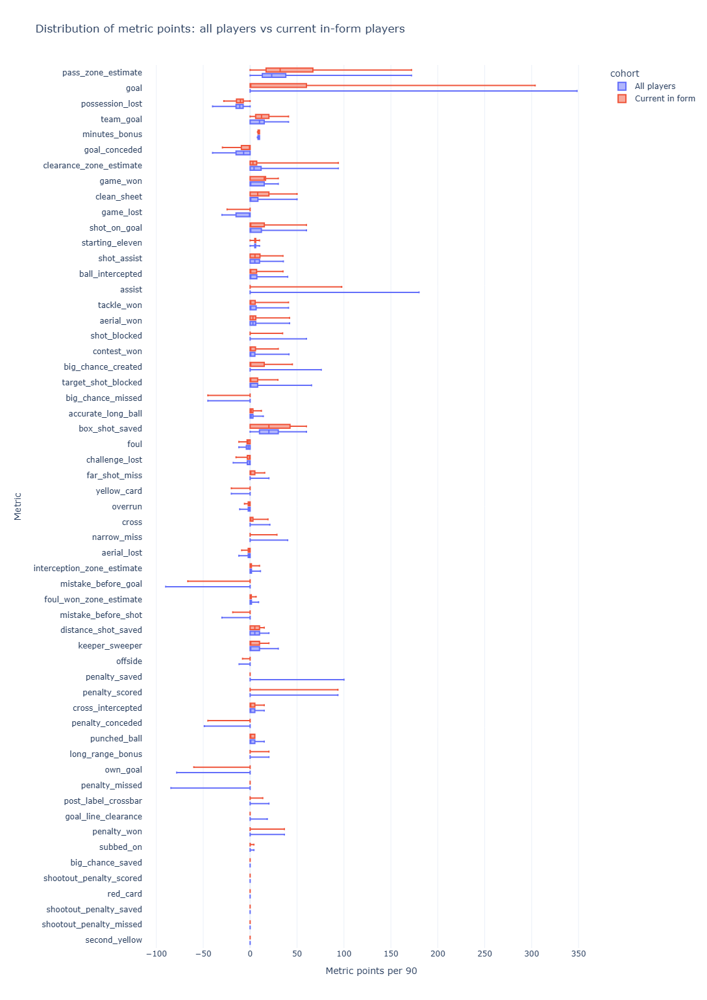

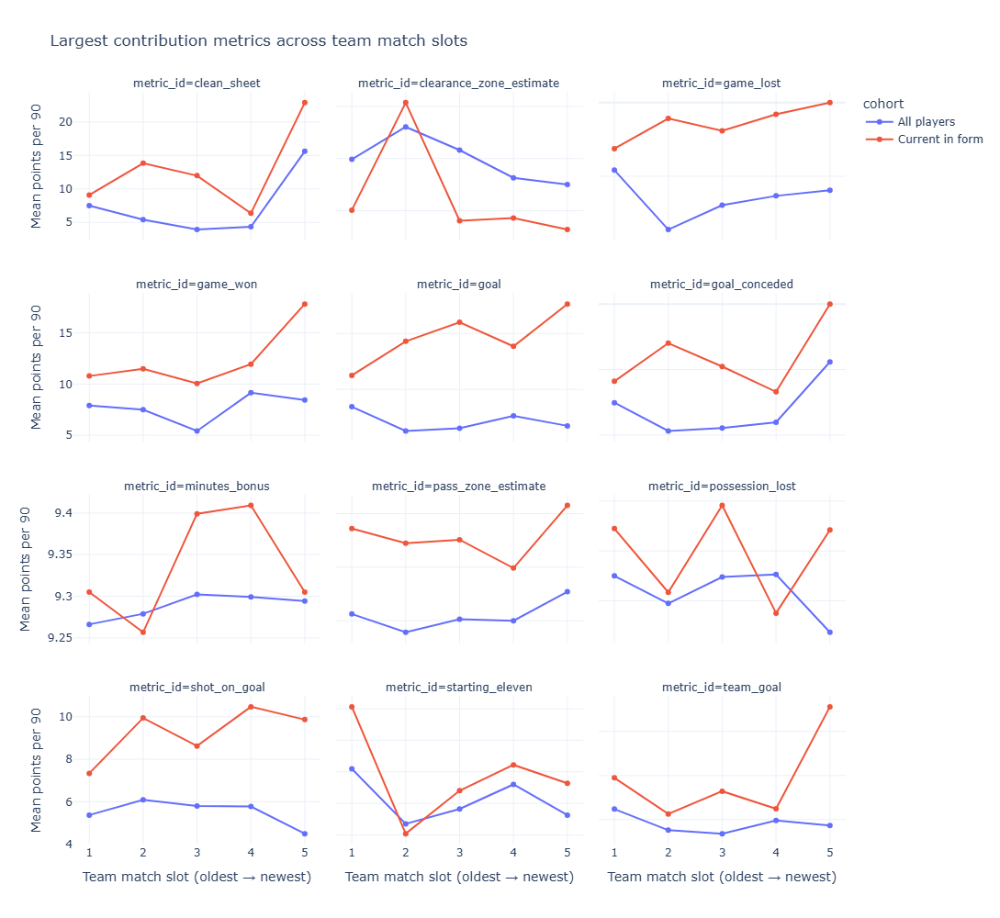

In [8]:
descriptive = metrics.loc[metrics.minutes_played >= MINIMUM_MINUTES].merge(
    current_form[['team_id', 'player_id', 'in_form']], on=['team_id', 'player_id'],
    how='left', validate='many_to_one')
all_rows = descriptive.assign(cohort='All players')
form_rows = descriptive.loc[descriptive.in_form.fillna(False)].assign(cohort='Current in form')
comparison = pd.concat([all_rows, form_rows], ignore_index=True)
contribution_order = descriptive.groupby('metric_id').metric_points.apply(lambda s: s.abs().sum()).sort_values(ascending=False).index.tolist()
fig = px.box(comparison, x='points_per_90', y='metric_id', color='cohort',
    category_orders={'metric_id': contribution_order}, points=False,
    labels={'points_per_90': 'Metric points per 90', 'metric_id': 'Metric'},
    title='Distribution of metric points: all players vs current in-form players')
fig.update_layout(height=max(1000, len(contribution_order)*27), margin=dict(l=220))
show_figure(fig)

means = comparison.groupby(['metric_id', 'slot', 'cohort'], as_index=False).agg(
    mean_points=('metric_points', 'mean'), mean_per_90=('points_per_90', 'mean'), appearances=('player_id', 'size'))
top_metrics = contribution_order[:12]
fig = px.line(means.loc[means.metric_id.isin(top_metrics)], x='slot', y='mean_per_90',
    color='cohort', facet_col='metric_id', facet_col_wrap=3, markers=True,
    hover_data=['mean_points', 'appearances'], title='Largest contribution metrics across team match slots',
    labels={'slot': 'Team match slot (oldest → newest)', 'mean_per_90': 'Mean points per 90'})
fig.update_yaxes(matches=None)
fig.update_xaxes(dtick=1)
fig.update_layout(height=1000)
show_figure(fig)

## Select a metric: player trajectories and next-match results

Use the dropdown inside the chart. Left: up to `DETAIL_PLAYERS` players with the
largest absolute contribution to the chosen metric, coloured by position. Right:
every evaluated next-match forecast, coloured by **pre-match** form status. The
diagonal is a perfect forecast. Player trajectories use actual points; prediction
comparisons use points per 90. Hover includes dates, competition and opponent.

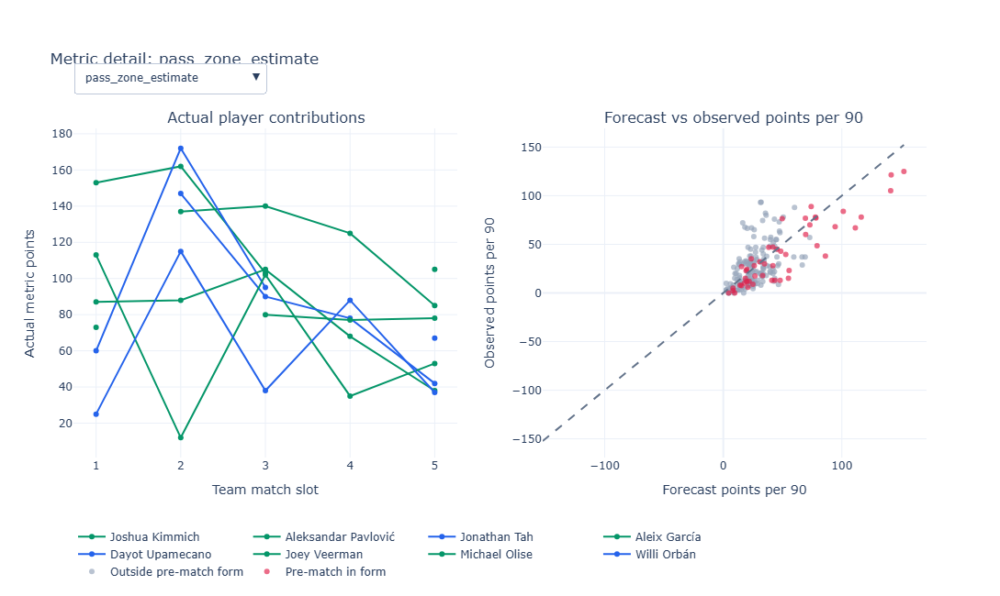

In [9]:
detail = make_subplots(rows=1, cols=2, subplot_titles=['Actual player contributions', 'Forecast vs observed points per 90'])
colors = {'GK': '#7c3aed', 'DEF': '#2563eb', 'MID': '#059669', 'FWD': '#d97706'}
ranges, buttons = [], []
for metric_index, metric in enumerate(contribution_order):
    start = len(detail.data)
    subset = descriptive.loc[descriptive.metric_id == metric]
    leaders = subset.groupby(['team_id', 'player_id']).metric_points.apply(lambda s: s.abs().sum()).nlargest(DETAIL_PLAYERS).index
    for team_id, player_id in leaders:
        player = subset.loc[(subset.team_id == team_id) & (subset.player_id == player_id)].sort_values('slot')
        first = player.iloc[0]
        # Reindex to all team slots, retaining absence gaps in the line.
        slots = metadata.loc[metadata.team_id == team_id].slot.tolist()
        player = player.set_index('slot').reindex(slots).reset_index()
        hover = [f"{first.player_name} ({first.position})<br>{r.kickoff}<br>{r.opponent} / {r.competition}"
                 if pd.notna(r.kickoff) else f'{first.player_name}: missing appearance'
                 for r in player.itertuples()]
        detail.add_trace(go.Scatter(x=player.slot, y=player.metric_points, mode='lines+markers',
            connectgaps=False, name=first.player_name, line=dict(color=colors[first.position]),
            text=hover, hovertemplate='%{text}<br>Slot %{x}: %{y} points<extra></extra>', visible=metric_index == 0), row=1, col=1)
    tested = evaluations.loc[evaluations.metric_id == metric]
    for in_form, name, color in [(False, 'Outside pre-match form', '#94a3b8'), (True, 'Pre-match in form', '#e11d48')]:
        points = tested.loc[tested.in_form == in_form]
        hover = [f'{r.player_name} ({r.position})<br>{r.kickoff}<br>{r.opponent} / {r.competition}<br>Earlier appearances: {r.history_count}' for r in points.itertuples()]
        detail.add_trace(go.Scatter(x=points.predicted_per_90, y=points.points_per_90,
            mode='markers', name=name, marker=dict(color=color, opacity=.65), text=hover,
            hovertemplate='%{text}<br>Forecast %{x:.1f}<br>Actual %{y:.1f}<extra></extra>', visible=metric_index == 0), row=1, col=2)
    bound = max(1, tested.points_per_90.abs().max() if len(tested) else 1,
                tested.predicted_per_90.abs().max() if len(tested) else 1)
    detail.add_trace(go.Scatter(x=[-bound, bound], y=[-bound, bound], mode='lines',
        line=dict(color='#64748b', dash='dash'), showlegend=False, hoverinfo='skip', visible=metric_index == 0), row=1, col=2)
    ranges.append((start, len(detail.data), metric))
for start, end, metric in ranges:
    buttons.append(dict(label=metric, method='update', args=[
        {'visible': [start <= i < end for i in range(len(detail.data))]},
        {'title': f'Metric detail: {metric}', 'xaxis2.autorange': True, 'yaxis2.autorange': True,
         'yaxis.autorange': True}]))
detail.update_layout(title=f'Metric detail: {contribution_order[0]}', height=650,
    updatemenus=[dict(buttons=buttons, x=0, y=1.2, xanchor='left', yanchor='top')],
    margin=dict(t=140), legend=dict(orientation='h', y=-.2))
detail.update_xaxes(title_text='Team match slot', dtick=1, row=1, col=1)
detail.update_yaxes(title_text='Actual metric points', row=1, col=1)
detail.update_xaxes(title_text='Forecast points per 90', row=1, col=2)
detail.update_yaxes(title_text='Observed points per 90', row=1, col=2)
show_figure(detail)

## Reading the result

Use position-specific green metrics as candidates for repeatable contributions.
Amber requires demonstrated repeatability in the pre-match form cohort. Red means
the metric failed this configured prediction approach with adequate evidence;
it is not a claim that the metric can never be predicted by another model.
Grey calls for more evidence rather than forced inclusion or exclusion.

This window mixes competitions and opponents and includes only source-eligible
players. Source failures, short appearances, small form cohorts and proxy awards
limit the interpretation. No opponent adjustment or longer-term validation is
added. Save the notebook after rerunning to retain updated tables and charts.

In [10]:
display(positions.groupby(['evidence_status', 'classification']).size().rename('Position/metric groups').to_frame())
display(Markdown('**All position-specific metrics, including unclassified and unsupported entries:**'))
display(positions[['metric_id', 'position', 'classification', 'evidence_status',
    'all_wape', 'all_recurrence', 'form_wape', 'form_recurrence']].round(3))
assert evaluations.empty or evaluations.latest_history_kickoff.lt(evaluations.kickoff).all()
print('Award reconciliation and strict pre-kickoff history checks passed.')

,,Position/metric groups
evidence_status,classification,
insufficient evidence,Unclassified,182
sufficient,Generally consistent,22
unsupported,Unclassified,109


**All position-specific metrics, including unclassified and unsupported entries:**

,metric_id,position,classification,evidence_status,all_wape,all_recurrence,form_wape,form_recurrence
0,goal,GK,Unclassified,insufficient evidence,NaN,NaN,NaN,NaN
1,goal,DEF,Unclassified,insufficient evidence,1.517,0.125,3.017,0.000
2,goal,MID,Unclassified,insufficient evidence,1.698,0.192,1.399,0.250
3,goal,FWD,Unclassified,insufficient evidence,1.392,0.409,1.432,0.455
4,penalty_saved,GK,Unclassified,insufficient evidence,NaN,0.000,NaN,NaN
5,penalty_scored,GK,Unclassified,insufficient evidence,NaN,NaN,NaN,NaN
6,penalty_scored,DEF,Unclassified,insufficient evidence,NaN,NaN,NaN,NaN
7,penalty_scored,MID,Unclassified,insufficient evidence,NaN,NaN,NaN,NaN
8,penalty_scored,FWD,Unclassified,insufficient evidence,1.831,0.250,1.831,0.250
9,assist,GK,Unclassified,insufficient evidence,NaN,NaN,NaN,NaN


Award reconciliation and strict pre-kickoff history checks passed.
